# Importing Required Libraries

In [1]:
import pandas as pd 
import numpy as np 
import sys
import warnings
import itertools
warnings.filterwarnings("ignore")
from pandas.plotting import autocorrelation_plot
from statsmodels.graphics.tsaplots import plot_acf
from matplotlib import pyplot as plt
from pandas.plotting import lag_plot
import statsmodels.api as sm
import statsmodels.tsa.api as smt
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
%matplotlib inline
import datetime
import calendar
import seaborn as sns
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

Importing the Dataset

In [2]:
data = pd.read_excel('champagn.xlsx')
data.head()

,Month,Sales
0,1964-01,2815
1,1964-02,2672
2,1964-03,2755
3,1964-04,2721
4,1964-05,2946


Creating a date range

In [3]:
dates = pd.date_range(start='1964-01-01', freq='MS', periods=len(data))
dates[0:5]

DatetimeIndex(['1964-01-01', '1964-02-01', '1964-03-01', '1964-04-01',
               '1964-05-01'],
              dtype='datetime64[us]', freq='MS')

In [4]:
data.set_index(dates, inplace=True)
data.drop('Month', axis=1, inplace=True)

# Modeling

In [5]:
train = (data[data.index < '1969-10-01'])
test  = (data[data.index >= '1969-10-01'])

# Model 1: Auto Regressive

Auto regression model creates a lag data so that correlation of the created lag is high with the original data.
No. of lag can be defined manually by seeing ACF plot. By default the algorithm shows the best lag.

In [6]:
lags = 12
model = AutoReg(train, lags=lags)
model_fit = model.fit()

In [7]:
lags_statistically = lags
coefficients = model_fit.params

print(f"Lags considered statistically: {lags_statistically}")
print(f"Coefficients (beta values):\n{coefficients}")

Lags considered statistically: 12
Coefficients (beta values):
const        774.861360
Sales.L1       0.068774
Sales.L2      -0.106691
Sales.L3       0.104460
Sales.L4      -0.145569
Sales.L5       0.070221
Sales.L6      -0.099998
Sales.L7       0.091160
Sales.L8      -0.117216
Sales.L9       0.036002
Sales.L10     -0.087992
Sales.L11      0.170959
Sales.L12      0.940454
dtype: float64


The no of best lag for this data is 11 and all the correlation of the lags with the original sales is listed

In [8]:
predictions = model_fit.predict(start=len(train),
                                end=len(train) + len(test) - 1,
                                dynamic=False)

In [9]:
print('The first test value in Sales :', test.values[1],
      'and its Predicted value : ', predictions.values[1])

The first test value in Sales : [10803] and its Predicted value :  11124.162022696051


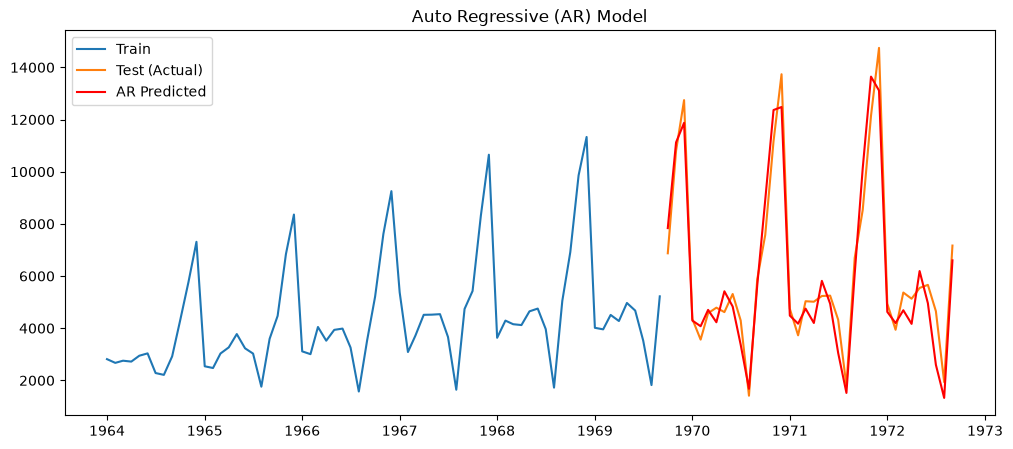

AR RMSE: 873.167636421451


In [10]:
plt.figure(figsize=(12, 5))
plt.plot(train.index, train['Sales'], label='Train')
plt.plot(test.index, test['Sales'], label='Test (Actual)')
plt.plot(test.index, predictions, label='AR Predicted', color='red')
plt.title('Auto Regressive (AR) Model')
plt.legend()
plt.show()

rmse_ar = np.sqrt(mean_squared_error(test['Sales'], predictions))
print("AR RMSE:", rmse_ar)

# Model 2: ARMA

In [11]:
arma_model = ARIMA(train, order=(2, 0, 2))
arma_fit   = arma_model.fit()

print(arma_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   69
Model:                 ARIMA(2, 0, 2)   Log Likelihood                -607.756
Date:                Tue, 17 Nov 2026   AIC                           1227.513
Time:                        10:09:08   BIC                           1240.917
Sample:                    01-01-1964   HQIC                          1232.831
                         - 09-01-1969                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       4373.4650    394.853     11.076      0.000    3599.566    5147.364
ar.L1          0.9348      0.100      9.318      0.000       0.738       1.131
ar.L2         -0.9125      0.097     -9.384      0.0

ARMA RMSE: 3288.241022623068


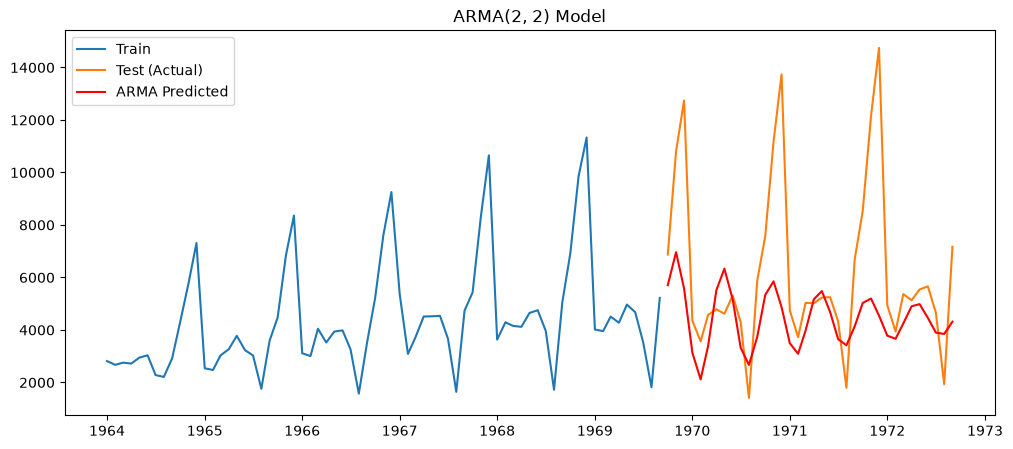

In [12]:
predictions_arma = arma_fit.predict(start=len(train),
                                    end=len(train) + len(test) - 1)

rmse_arma = np.sqrt(mean_squared_error(test['Sales'], predictions_arma))
print("ARMA RMSE:", rmse_arma)

plt.figure(figsize=(12, 5))
plt.plot(train.index, train['Sales'], label='Train')
plt.plot(test.index, test['Sales'], label='Test (Actual)')
plt.plot(test.index, predictions_arma, label='ARMA Predicted', color='red')
plt.title('ARMA(2, 2) Model')
plt.legend()
plt.show()

ARMA RMSE: 3288.241022623068


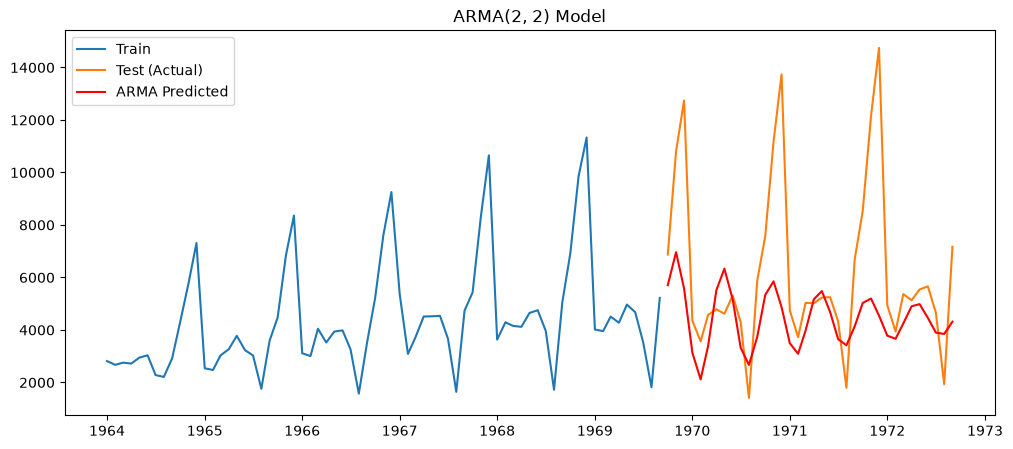

In [13]:
predictions_arma = arma_fit.predict(start=len(train),
                                    end=len(train) + len(test) - 1)

rmse_arma = np.sqrt(mean_squared_error(test['Sales'], predictions_arma))
print("ARMA RMSE:", rmse_arma)

plt.figure(figsize=(12, 5))
plt.plot(train.index, train['Sales'], label='Train')
plt.plot(test.index, test['Sales'], label='Test (Actual)')
plt.plot(test.index, predictions_arma, label='ARMA Predicted', color='red')
plt.title('ARMA(2, 2) Model')
plt.legend()
plt.show()

# Model 3: ARIMA

In [14]:
arima_model = ARIMA(train, order=(2, 1, 2))
arima_fit   = arima_model.fit()

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   69
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -603.631
Date:                Tue, 17 Nov 2026   AIC                           1217.262
Time:                        10:09:09   BIC                           1228.359
Sample:                    01-01-1964   HQIC                          1221.659
                         - 09-01-1969                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2117      0.155     -1.365      0.172      -0.516       0.092
ar.L2          0.1987      0.158      1.260      0.208      -0.110       0.508
ma.L1         -0.0294      0.105     -0.281      0.7

ARIMA RMSE: 3487.369249730203


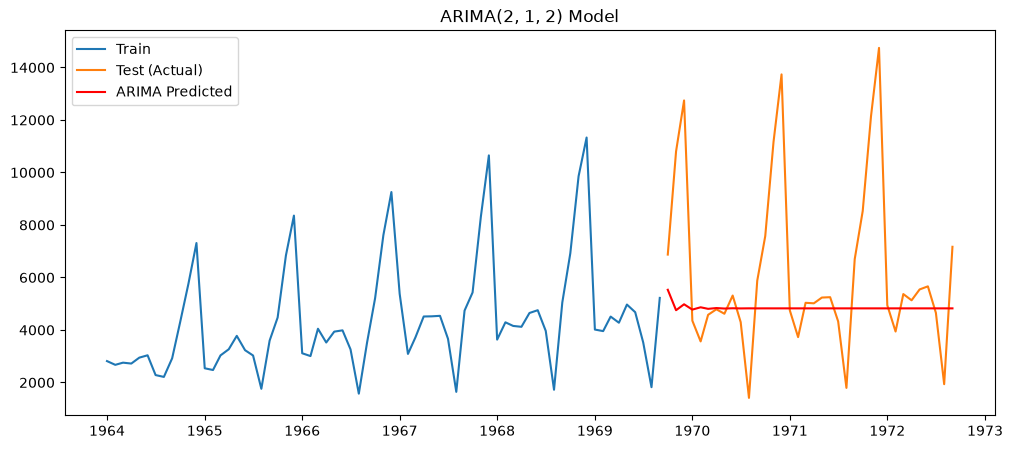

In [15]:
predictions_arima = arima_fit.predict(start=len(train),
                                      end=len(train) + len(test) - 1)

rmse_arima = np.sqrt(mean_squared_error(test['Sales'], predictions_arima))
print("ARIMA RMSE:", rmse_arima)

plt.figure(figsize=(12, 5))
plt.plot(train.index, train['Sales'], label='Train')
plt.plot(test.index, test['Sales'], label='Test (Actual)')
plt.plot(test.index, predictions_arima, label='ARIMA Predicted', color='red')
plt.title('ARIMA(2, 1, 2) Model')
plt.legend()
plt.show()

# Model 4: SARIMA

In [16]:
sarima_model = SARIMAX(train['Sales'],
                       order=(1, 1, 1),
                       seasonal_order=(1, 1, 1, 12),
                       enforce_stationarity=False,
                       enforce_invertibility=False)
sarima_fit = sarima_model.fit(disp=False)

print(sarima_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Sales   No. Observations:                   69
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -331.994
Date:                            Tue, 17 Nov 2026   AIC                            673.988
Time:                                    10:09:10   BIC                            682.677
Sample:                                01-01-1964   HQIC                           677.173
                                     - 09-01-1969                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0598      0.164      0.365      0.715      -0.261       0.381
ma.L1         -1.0000      0.261   

SARIMA RMSE: 811.2124273616741


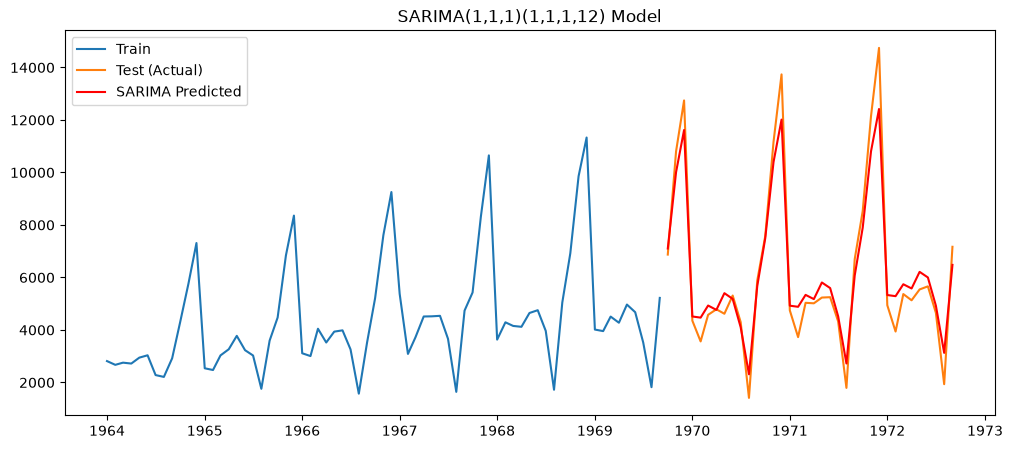

In [17]:
predictions_sarima = sarima_fit.predict(start=len(train),
                                        end=len(train) + len(test) - 1)

rmse_sarima = np.sqrt(mean_squared_error(test['Sales'], predictions_sarima))
print("SARIMA RMSE:", rmse_sarima)

plt.figure(figsize=(12, 5))
plt.plot(train.index, train['Sales'], label='Train')
plt.plot(test.index, test['Sales'], label='Test (Actual)')
plt.plot(test.index, predictions_sarima, label='SARIMA Predicted', color='red')
plt.title('SARIMA(1,1,1)(1,1,1,12) Model')
plt.legend()
plt.show()

# Model Comparison

In [18]:
rmse_ar = np.sqrt(mean_squared_error(test['Sales'], predictions))

results = pd.DataFrame({
    'Model': ['AR', 'ARMA', 'ARIMA', 'SARIMA'],
    'RMSE':  [rmse_ar, rmse_arma, rmse_arima, rmse_sarima]
})
results

,Model,RMSE
0,AR,873.167636
1,ARMA,3288.241023
2,ARIMA,3487.369250
3,SARIMA,811.212427
